## Sentiment analysis on Climate change data. 

- We perform sentiment analysis in this climate change data.We want to see sentiments across groups ,temporal shift in sentiment and topic  discussed.

- Importing necesssary libararies

In [85]:
import pandas as pd 
import numpy as np
import seaborn as sns
import math
import nltk
import matplotlib.pyplot as plt
from transformers import pipeline
from tqdm import tqdm
import warnings
from nltk.corpus import stopwords
from collections import Counter
from bertopic import BERTopic
from wordcloud import WordCloud
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.decomposition import LatentDirichletAllocation
nltk.download('stopwords')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer,CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline,Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
warnings.filterwarnings("ignore")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\binay\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


- Reading the preprocessed file from the final.csv from Data acquisiton and engineering notebook.

In [86]:
df = pd.read_csv("final.csv")
df.head()

,Date,subreddit,text,text_length,engagement_score
0,2025-01-13 21:55:09,climatechange,We’ve Crossed a Key Threshold for Climate Chan...,34,9.413444
1,2024-12-23 11:51:10,climatechange,Venezuela is the first country to lose all of ...,21,8.860357
2,2024-10-18 18:01:14,climatechange,Harris win would be a 'big relief' for climate...,35,8.493310
3,2023-10-20 00:58:25,climatechange,Billions of crabs went missing around Alaska. ...,70,8.920923
4,2024-10-07 17:10:29,climatechange,We’re Not Prepared for What Hurricane Milton M...,187,8.857373


- ### Using VADER (a rule based sentiment analysis) to map the sentiment of each text (for know I caluated both scores and labels)

In [87]:
analyzer = SentimentIntensityAnalyzer()

def get_vader_sentiment_score(text):
    return analyzer.polarity_scores(text)['compound']

def get_vader_sentiment_label(score):
    if score >= 0.05:
        return 'positive'
    elif score <= -0.05:
        return 'negative'
    else:
        return 'neutral'

df['vader_sentiment_score'] = df['text'].apply(get_vader_sentiment_score)
df['vader_sentiment_label'] = df['vader_sentiment_score'].apply(get_vader_sentiment_label)



In [88]:
df.head()

,Date,subreddit,text,text_length,engagement_score,vader_sentiment_score,vader_sentiment_label
0,2025-01-13 21:55:09,climatechange,We’ve Crossed a Key Threshold for Climate Chan...,34,9.413444,-0.5267,negative
1,2024-12-23 11:51:10,climatechange,Venezuela is the first country to lose all of ...,21,8.860357,-0.4019,negative
2,2024-10-18 18:01:14,climatechange,Harris win would be a 'big relief' for climate...,35,8.493310,0.9642,positive
3,2023-10-20 00:58:25,climatechange,Billions of crabs went missing around Alaska. ...,70,8.920923,-0.4754,negative
4,2024-10-07 17:10:29,climatechange,We’re Not Prepared for What Hurricane Milton M...,187,8.857373,-0.7694,negative


- ###  Using Transformer Model

In [89]:

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-roberta-base-sentiment",
    truncation=True
)

def get_bert_sentiment_with_score(texts):
    labels = []
    scores = []
    for text in tqdm(texts, desc="Running BERT Sentiment Analysis"):
        try:
            output = sentiment_pipeline(text[:512])[0]  # Truncate to 512 characters beacause of BERT's input size limit
            labels.append(output['label'])
            scores.append(output['score'])
        except Exception as e:
            print(f"Error processing: {text[:100]}... \n{e}")
            labels.append("ERROR")
            scores.append(0.0)
    return labels, scores

raw_labels, raw_scores = get_bert_sentiment_with_score(df['text'].tolist())

df['bert_sentiment_raw'] = raw_labels
df['bert_sentiment_score'] = raw_scores

label_map = {
    'LABEL_0': 'negative',
    'LABEL_1': 'neutral',
    'LABEL_2': 'positive'
}
df['bert_sentiment_label'] = df['bert_sentiment_raw'].map(label_map).fillna('unknown')

# Save the DataFrame with sentiment results beacuase it takes a long time to train thi model in the dataset
df.to_csv("reddit_climate_sentiment_bert.csv", index=True)



Running BERT Sentiment Analysis: 100%|██████████| 9948/9948 [13:34<00:00, 12.22it/s]


In [90]:
df.sample(5)

,Date,subreddit,text,text_length,engagement_score,vader_sentiment_score,vader_sentiment_label,bert_sentiment_raw,bert_sentiment_score,bert_sentiment_label
1274,2024-02-19 23:46:28,climateskeptics,Climate alarmist having mental breakdown Lmao,6,6.813445,0.5994,positive,LABEL_0,0.815891,negative
9158,2021-01-16 10:18:02,ZeroWaste,Can we get a rule against unconstructive criti...,369,8.794673,0.8992,positive,LABEL_0,0.896138,negative
8857,2020-10-27 21:00:27,sustainability,Burger King to launch reusable containers pilo...,44,6.265301,0.0000,neutral,LABEL_1,0.632089,neutral
5773,2021-02-20 11:57:52,energy,Texas governor deflects blame with ‘deeply mis...,66,6.688355,-0.6597,negative,LABEL_0,0.789467,negative
3507,2020-10-08 03:38:30,Collapse,Recycling was a lie — a big lie — to sell more...,76,8.613957,-0.2280,negative,LABEL_0,0.482463,negative


- Comparison between labels determined by vader and BERT 

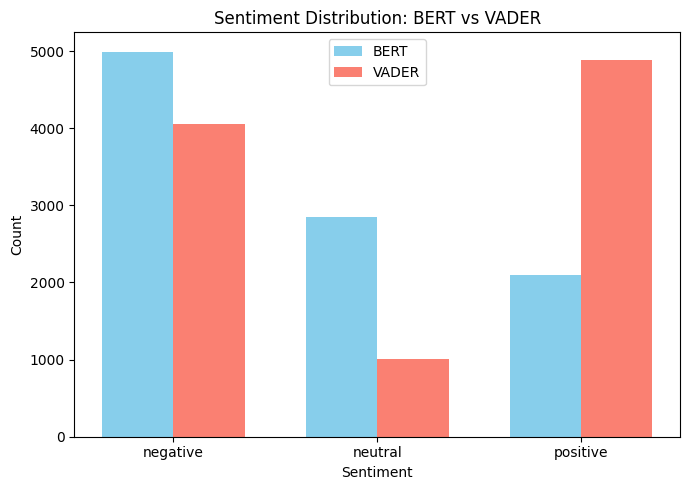

In [91]:

sentiment_types = ['negative', 'neutral', 'positive']
bert_counts = df['bert_sentiment_label'].value_counts().reindex(sentiment_types, fill_value=0)
vader_counts = df['vader_sentiment_label'].value_counts().reindex(sentiment_types, fill_value=0)

x = np.arange(len(sentiment_types))
width = 0.35

plt.figure(figsize=(7, 5))
plt.bar(x - width/2, bert_counts, width, label='BERT', color='skyblue')
plt.bar(x + width/2, vader_counts, width, label='VADER', color='salmon')
plt.xticks(x, sentiment_types)
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.title('Sentiment Distribution: BERT vs VADER')
plt.legend()
plt.tight_layout()
plt.show()


- There is a clear discrepancy in sentiment_label from Vader and  BERT using Hugging Face’s "cardiffnlp/twitter-roberta-base-sentiment" model.Let's look into what type of posts are considered complete opposite by these two methods.
- Vader is confidently picking up positive and negative but less prone to classfiy neutral as neutral.
- BERT sees many posts lacking emotional extremities.

In [92]:
# Filter rows where BERT label is positive and VADER label is negative
contradictory = df[(df['bert_sentiment_label'] == 'positive') & (df['vader_sentiment_label'] == 'negative')][['text', 'vader_sentiment_label', 'bert_sentiment_label']]
contradictory.head()


,text,vader_sentiment_label,bert_sentiment_label
7,China built more solar power in the last 8 mon...,negative,positive
134,As parts of Florida went dark from Helene and ...,negative,positive
370,Over 300 Japanese weather stations report hott...,negative,positive
383,Temperatures Rising: NASA Confirms 2024 Warmes...,negative,positive
498,The US is about to make a sharp turn on climat...,negative,positive


In [93]:
contradictory['text'].head(5).to_list()

['China built more solar power in the last 8 months than all the nuclear power built in the entire world in the entire history of human civilisation.  So much negativity in the comments. I think no matter how you look at this, it’s a big step in the right direction',
 'As parts of Florida went dark from Helene and Milton, the lights stayed on in this net-zero, storm-proof community   "They also boast some of the most sustainable, energy-efficient and hurricane-proof homes in the country:\xa0\n\n\nThe streets surrounding the homes are intentionally designed to flood so houses don’t.\xa0\n\n\nPower and internet lines are buried to avoid wind damage.\xa0\n\n\nThe sturdy concrete walls, hurricane-proof windows and doors are fortified with a layer of foam insulation, providing extra safety against the most violent storms."',
 'Over 300 Japanese weather stations report hottest November day in history November Heatwave 28 degrees in Japan in November is crazy.',
 'Temperatures Rising: NASA Co

- The results are quite interseting.Sometimes vader predicts correclty and sometimes bert predicts correclty.
- In case 1 : The post is positive.Vader fails and BeRT is correct.
- In case 2,3,4 : These post are negative .Vader succeds.
- In case 5: the post is postive.Vader fails and bert succeds.

- Reasons:
- Vader isn't able to truly undertand the context of the text beyond its rules.
- I decided that BERT is picking up on more nuanced languages that VADER is missing.

- ### Engagement_score based on sentiment labels

- From the previous notebook,we could clearly see three bins(one for 0-4,next 4-7.8 and 7.8 and above) for enagagement_score from its histplot.
- Let's see the count of posts in each sentiment-enagegement combination.


BERT Sentiment vs Engagement Bin:
engagement_bin        Low (0-4)  Medium (4-7.8)  High (7.8+)
bert_sentiment_label                                        
negative                     95            2916         1983
neutral                      53            1947          855
positive                     33            1169          897


<Figure size 700x500 with 0 Axes>

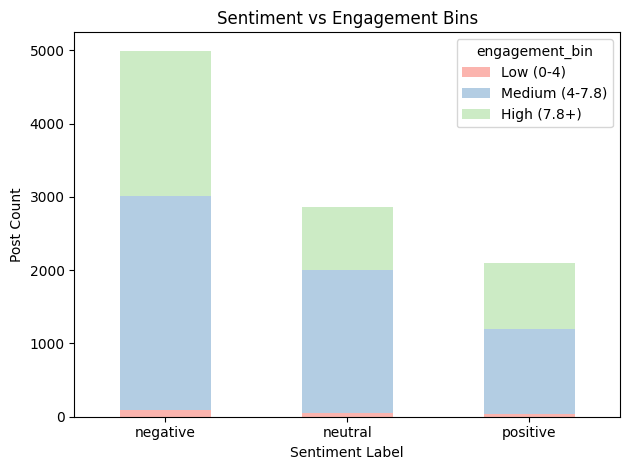

In [101]:
engagement_bins = [0, 4, 7.8, df['engagement_score'].max()]
engagement_labels = ['Low (0-4)', 'Medium (4-7.8)', 'High (7.8+)']
df['engagement_bin'] = pd.cut(df['engagement_score'], bins=engagement_bins, labels=engagement_labels, include_lowest=True)

bert_crosstab = pd.crosstab(df['bert_sentiment_label'], df['engagement_bin'])
print("BERT Sentiment vs Engagement Bin:")
print(bert_crosstab)

plt.figure(figsize=(7, 5))
bert_crosstab.plot(kind='bar', stacked=True, color=['#fbb4ae', '#b3cde3', '#ccebc5'])
plt.xlabel('Sentiment Label')
plt.ylabel('Post Count')
plt.title('Sentiment vs Engagement Bins')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


- 67% of high engagement posts (1983 out of 3735) are negative.It suggests that negativity drives more intercation.
- Negative posts are most common across all bins but especially in medium and high enagagement.
- only 22% of high engagement comments are neutral.
- Sentiment and engagement isnot linear as we think .Negative comments are both enagaging and high in number.

------- Across subreddits sentiments

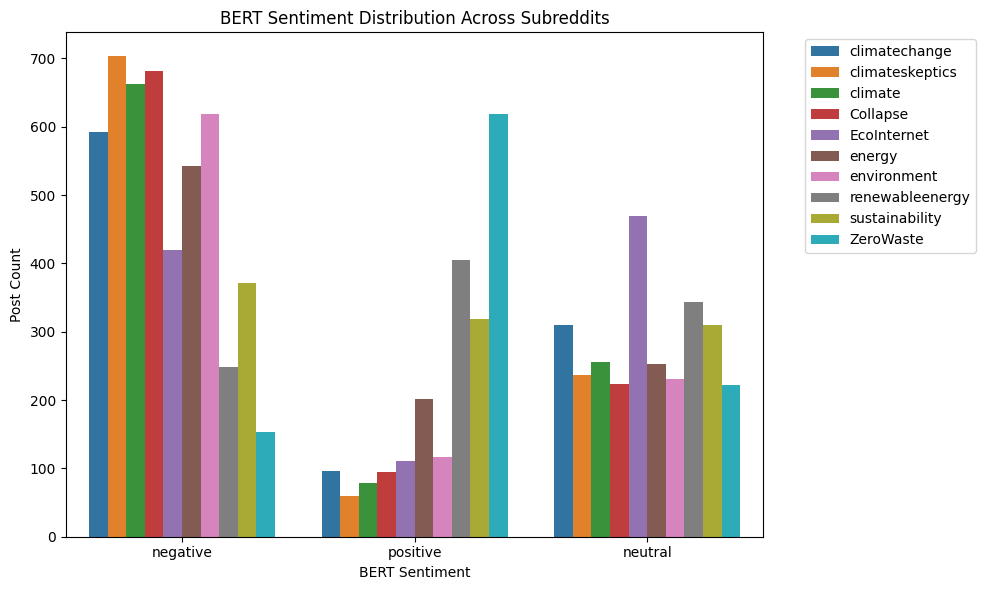

In [102]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='bert_sentiment_label', hue='subreddit')
plt.title("BERT Sentiment Distribution Across Subreddits")
plt.xlabel("BERT Sentiment")
plt.ylabel("Post Count")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


- We can clearly see the sentiments in subrredits like <b>climateskeptics</b> and <b>collapse</b> have higher number of negative  sentiments compared to postive or neutral comments.
- The number of postive sentiment is higher in <b>ZeroWaste</b> than negative or neutral posts.
- This can be accredited to the type of subreddit dicusiion group they are,climate skeptics and collapse tend to be more negative-mongering groups in comparison to ZeroWaste which is more about postivity.

- ### Emotion detection in the posts.

In [103]:
emotion_pipeline = pipeline(
    "text-classification",
    model= "SamLowe/roberta-base-go_emotions",
    return_all_scores=True,
    truncation=True,

)

In [104]:
df['text'] = df['text'].astype(str)
def batch_emotion_analysis(texts, batch_size=100, threshold=0.3):
    results = []
    for i in tqdm(range(0, len(texts), batch_size), desc="Running Emotion Detection"):
        batch = texts[i:i+batch_size]
        outputs = emotion_pipeline(batch, truncation=True, max_length=512)
        for output in outputs:
          
            emotions = [item for item in output if item['score'] > threshold]
           
            emotions_sorted = sorted(emotions, key=lambda x: x['score'], reverse=True)
          
            labels = [e['label'] for e in emotions_sorted]
            scores = [round(e['score'], 3) for e in emotions_sorted]
            results.append({'emotion_labels': labels, 'emotion_scores': scores})
    return results


emotion_results = batch_emotion_analysis(df['text'].tolist(), batch_size=32, threshold=0.3)


df['emotion_labels'] = [res['emotion_labels'] for res in emotion_results]
df['emotion_scores'] = [res['emotion_scores'] for res in emotion_results]


df.to_csv("reddit_emotion_output.csv", index=False)


Running Emotion Detection: 100%|██████████| 311/311 [15:11<00:00,  2.93s/it]


In [105]:
df[['text', 'emotion_labels', 'emotion_scores']].head()

,text,emotion_labels,emotion_scores
0,We’ve Crossed a Key Threshold for Climate Chan...,"[approval, neutral]","[0.59, 0.447]"
1,Venezuela is the first country to lose all of ...,[neutral],[0.712]
2,Harris win would be a 'big relief' for climate...,"[approval, optimism]","[0.354, 0.352]"
3,Billions of crabs went missing around Alaska. ...,[neutral],[0.358]
4,We’re Not Prepared for What Hurricane Milton M...,[neutral],[0.854]


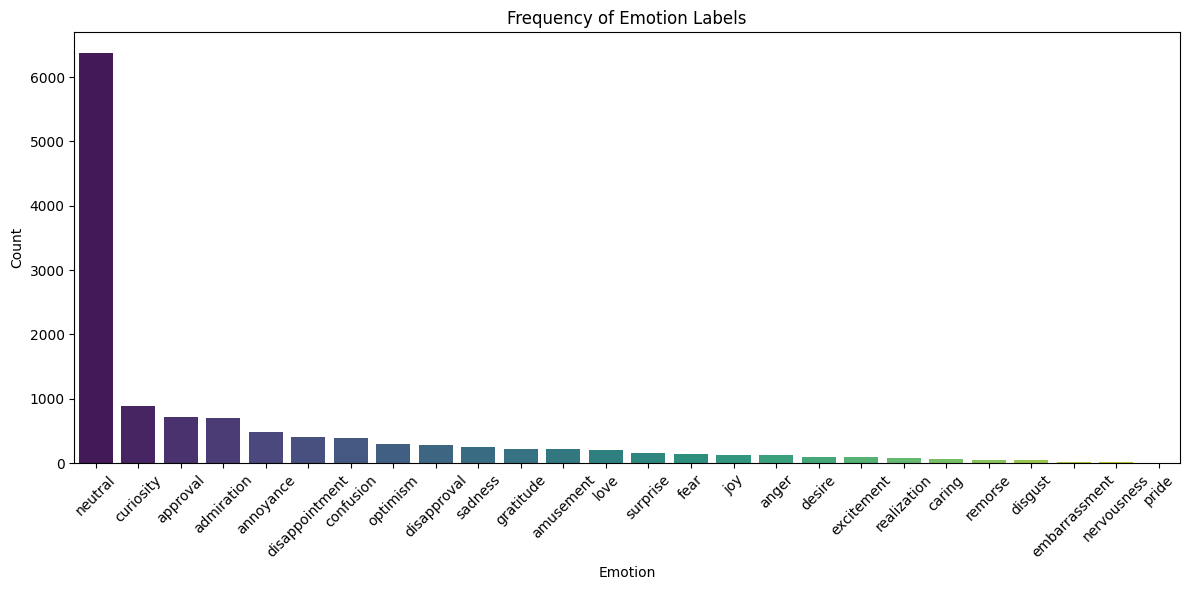

In [106]:
all_emotions = [emotion for labels in df['emotion_labels'] for emotion in labels]
emotion_counts = Counter(all_emotions)
emotion_df = pd.DataFrame(list(emotion_counts.items()), columns=['emotion', 'count']).sort_values(by='count', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(data=emotion_df, x='emotion', y='count', palette='viridis')
plt.xlabel('Emotion')
plt.ylabel('Count')
plt.title('Frequency of Emotion Labels')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

- We see most of the text having neutral emotion.

- Let's see the most common three word phrases in the posts that are marked as neutral.

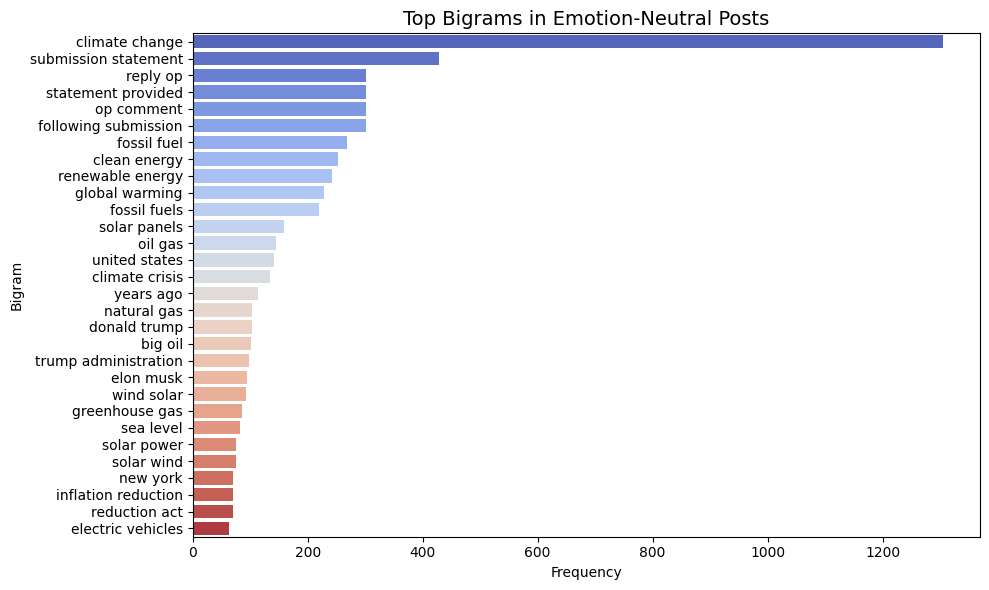

In [107]:
neutral_df = df[df['emotion_labels'].apply(lambda x: 'neutral' in x if isinstance(x, list) else False)]


vectorizer = CountVectorizer(ngram_range=(2, 2), # Using bigrams
                             stop_words='english', 
                             max_features=30)  

X = vectorizer.fit_transform(neutral_df['text'].astype(str))

ngram_freq = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())
ngram_counts = ngram_freq.sum().sort_values(ascending=False).reset_index()
ngram_counts.columns = ['bigram', 'count']


plt.figure(figsize=(10, 6))
sns.barplot(data=ngram_counts, x='count', y='bigram', palette='coolwarm')
plt.title("Top Bigrams in Emotion-Neutral Posts", fontsize=14)
plt.xlabel("Frequency")
plt.ylabel("Bigram")
plt.tight_layout()
plt.show()

- Climate change is the most frequent two-word phrase which is obvious.
- submission statement,reply op,statement provided seem to be metadata or automatically generated by reddit.
- fossil fuel,clean energy,renewable energy seems to be the most common two-word phrases.

- Let's check on other emotions if the results are same or not.

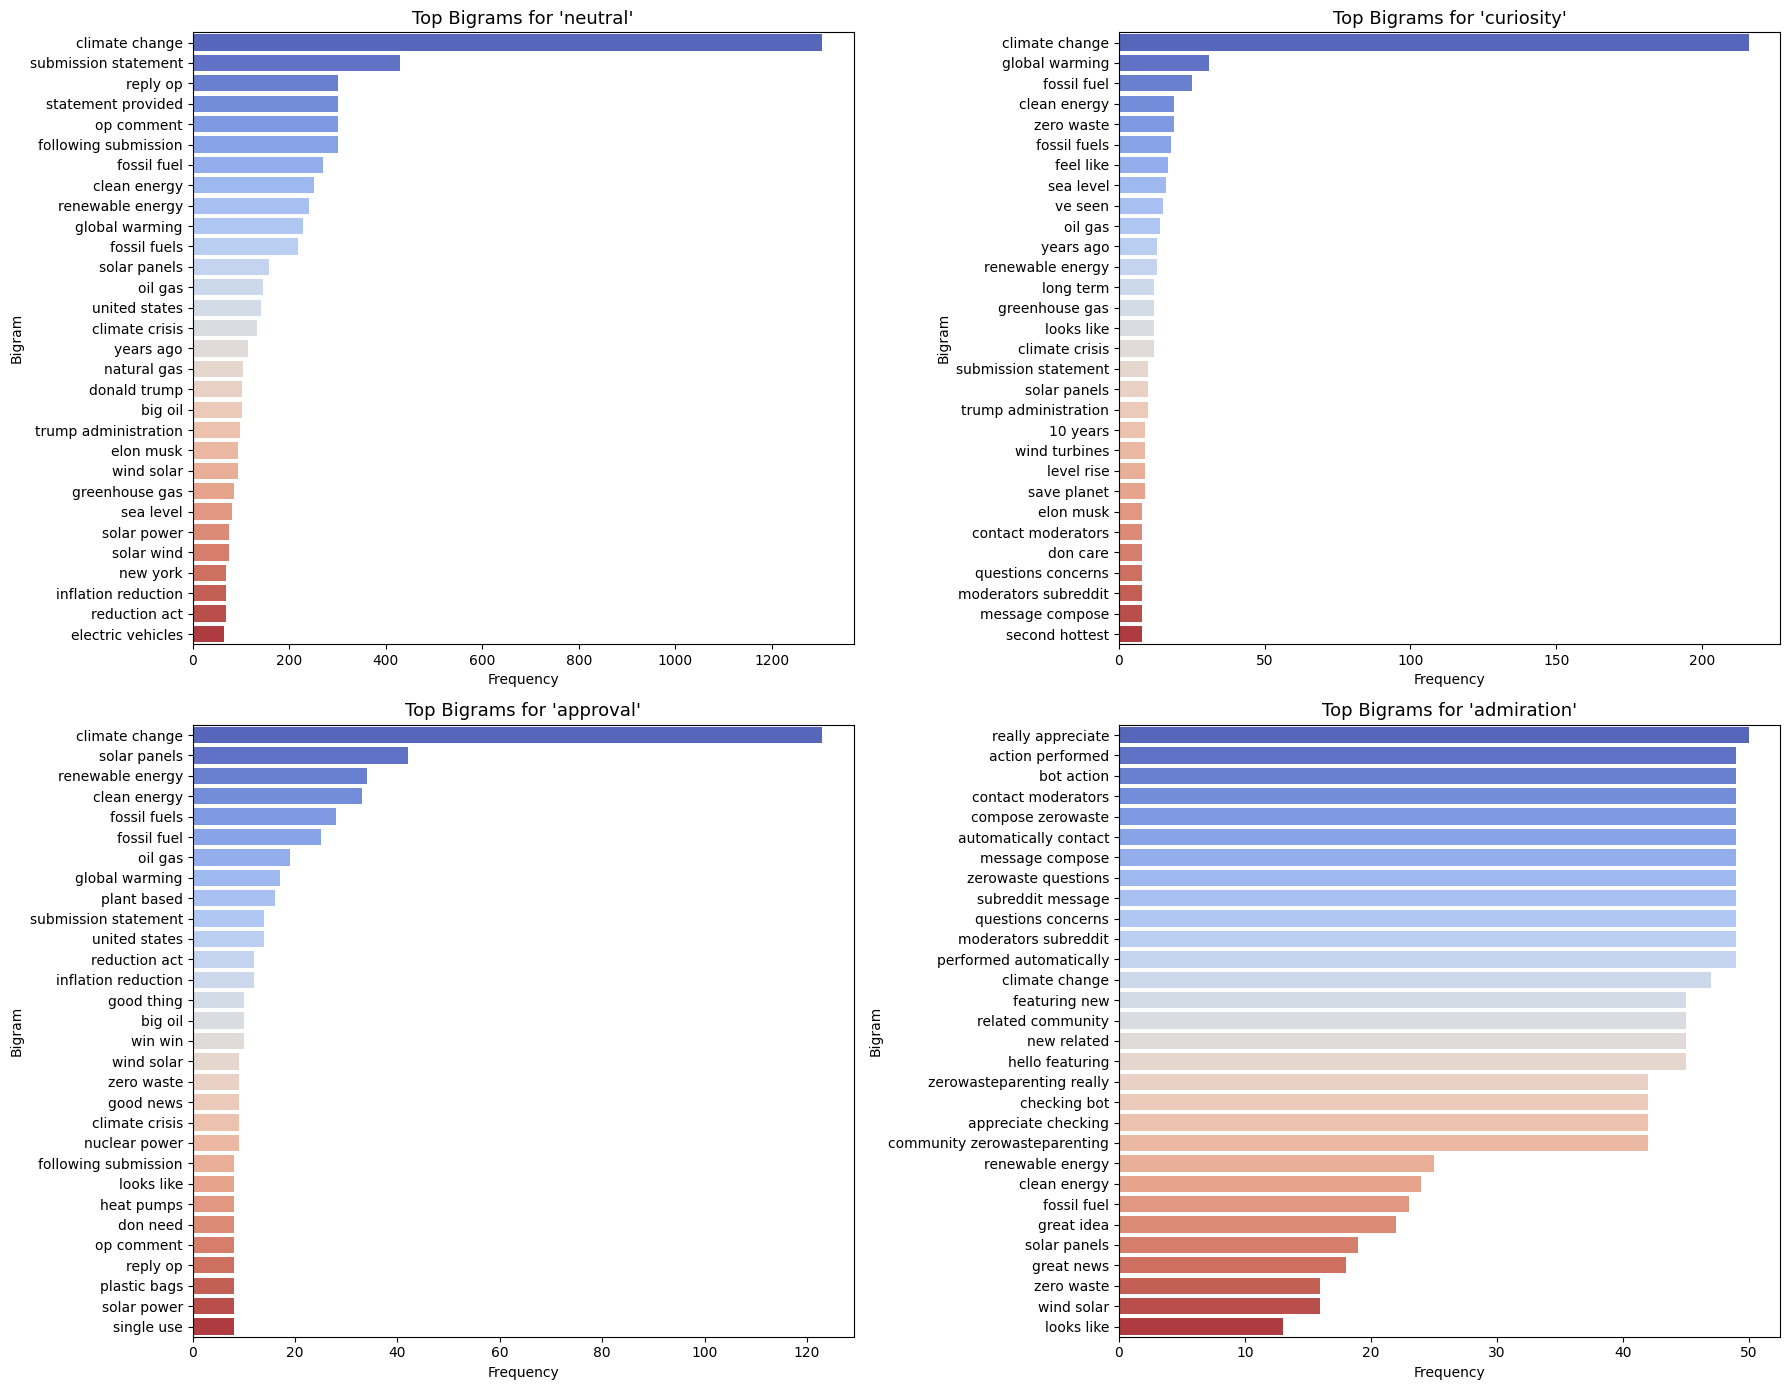

In [108]:

target_emotions = ['neutral', "curiosity", "approval", "admiration"]

fig, axes = plt.subplots(2, 2, figsize=(18, 14)) 
axes = axes.flatten()

for i, emotion in enumerate(target_emotions):
    emotion_df = df[df['emotion_labels'].apply(lambda x: emotion in x if isinstance(x, list) else False)]

    # Filter out empty/short texts
    emotion_df = emotion_df[emotion_df['text'].str.strip().astype(bool)]
    emotion_df = emotion_df[emotion_df['text'].str.split().str.len() >= 2]

    vectorizer = CountVectorizer(ngram_range=(2, 2), stop_words='english', max_features=30)
    X = vectorizer.fit_transform(emotion_df['text'].astype(str))

    if X.shape[1] > 0:
        ngram_freq = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())
        ngram_counts = ngram_freq.sum().sort_values(ascending=False).reset_index()
        ngram_counts.columns = ['bigram', 'count']

        sns.barplot(data=ngram_counts, x='count', y='bigram', ax=axes[i], palette='coolwarm')
        axes[i].set_title(f"Top Bigrams for '{emotion}'", fontsize=13)
        axes[i].set_xlabel("Frequency")
        axes[i].set_ylabel("Bigram")
    else:
        axes[i].set_title(f"No bigrams for '{emotion}'", fontsize=13)
        axes[i].axis('off')


for j in range(len(target_emotions), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()


- In other emotion label, those words like submission statement,reply op ,statement provided  aren't that frequent.
- So,these words with no inherent meaning for the context were responsible for neutral emotion labels.
- In other emotion labels,clean energy,fossil fuels are more commom Where users can show their emotions,

- ### Temporal analysis.

In [109]:
df["year"] = pd.to_datetime(df["Date"]).dt.to_period("Y").astype(str)
yearly = df.groupby("year")[["bert_sentiment_score", "engagement_score"]].mean().reset_index()

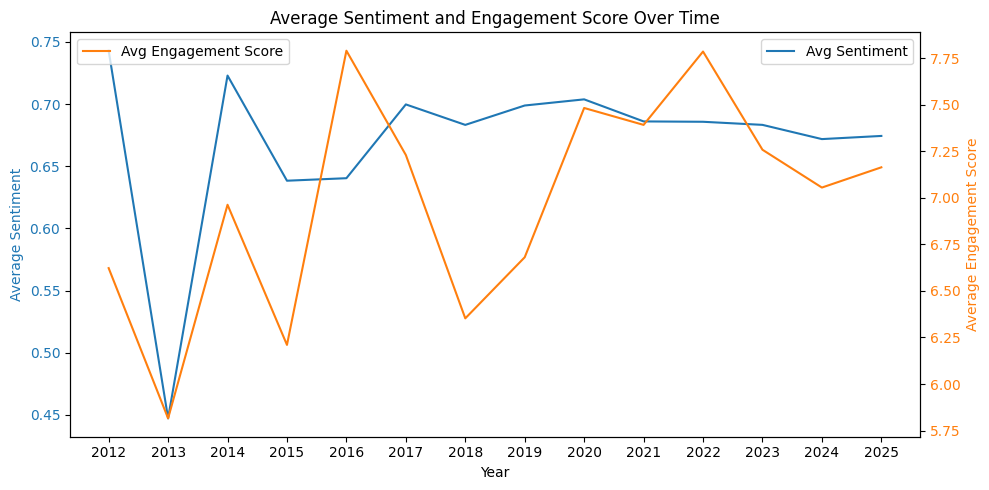

In [110]:

fig, ax1 = plt.subplots(figsize=(10, 5))

# Plot average sentiment
sns.lineplot(data=yearly, x="year", y="bert_sentiment_score", ax=ax1, label="Avg Sentiment", color="tab:blue")
ax1.set_ylabel("Average Sentiment", color="tab:blue")
ax1.tick_params(axis='y', labelcolor="tab:blue")

# Plot average engagement score on secondary y-axis
ax2 = ax1.twinx()
sns.lineplot(data=yearly, x="year", y="engagement_score", ax=ax2, label="Avg Engagement Score", color="tab:orange")
ax2.set_ylabel("Average Engagement Score", color="tab:orange")
ax2.tick_params(axis='y', labelcolor="tab:orange")

plt.title("Average Sentiment and Engagement Score Over Time")
ax1.set_xlabel("Year")
plt.xticks(rotation=45)
fig.tight_layout()
plt.show()



- The enagement score increases sharply during covid time meaning most of the users were active in Reddit becuase of more free time.
- There is high flucations in the year 2012-2015,either sharp rise or sharp fall.

- Let's see the total number of posts by year.

year
2012       3
2013       2
2014       6
2015      10
2016      49
2017     225
2018     546
2019    1339
2020    1065
2021    1046
2022    1424
2023    1287
2024    1707
2025    1239
Name: count, dtype: int64


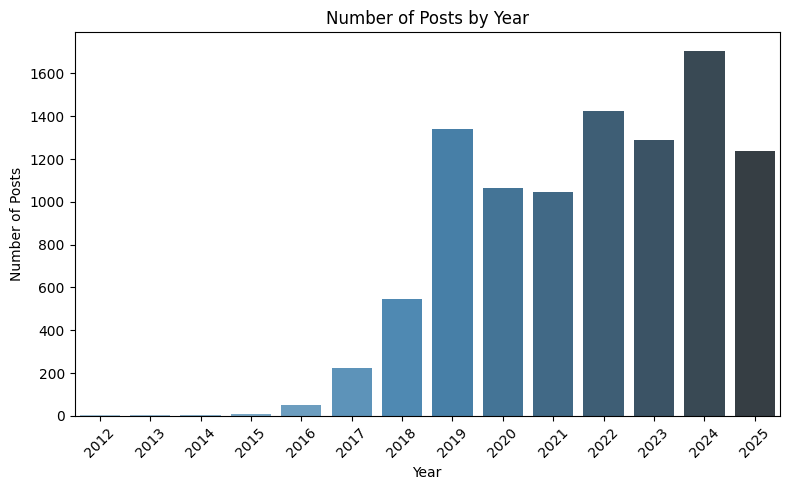

In [111]:

posts_per_year = df['year'].value_counts().sort_index()
print(posts_per_year)

# Optional: Plot the number of posts per year
plt.figure(figsize=(8, 5))
sns.barplot(x=posts_per_year.index, y=posts_per_year.values, palette='Blues_d')
plt.xlabel('Year')
plt.ylabel('Number of Posts')
plt.title('Number of Posts by Year')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

- The rapid flucations in average enagagement score and average is due to very few number of posts in those years .

- ## Most discussed topic over years

- Removing climate,climate change and change beacuse they are the obvious topic we would find in the text.

In [ ]:

custom_stop_words = ENGLISH_STOP_WORDS.union({'climate', 'change', 'climatechange'})

vectorizer_model = CountVectorizer(stop_words=custom_stop_words, ngram_range=(1, 2))


df['text_cleaned'] = df['text'].str.replace(
    r'\bclimate change\b|\bclimatechange\b|\bclimate\b',
    '',
    regex=True,
    case=False  
)

In [113]:
years = sorted(df['year'].unique())

topic_results = []

for year in years:
    year_df = df[df['year'] == year]
    texts = year_df['text_cleaned'].astype(str).tolist()

    if len(texts) < 10:  # Skip if too few posts
        print(f"Skipping {year} (only {len(texts)} posts)")
        continue

    vectorizer_model = CountVectorizer(stop_words="english", ngram_range=(1, 2))
    topic_model = BERTopic(vectorizer_model=vectorizer_model, verbose=False)

    topics, _ = topic_model.fit_transform(texts)
    topic_info = topic_model.get_topic_info()

    topic_info_filtered = topic_info[topic_info.Topic != -1]

    if topic_info_filtered.empty:
        print(f"No valid topics found for year {year}")
        continue

    top_topic = topic_info_filtered.iloc[0]

    topic_results.append({
        "year": year,
        "topic_id": top_topic['Topic'],
        "topic_size": top_topic['Count'],
        "topic_words": top_topic['Name']
    })
topic_summary_df = pd.DataFrame(topic_results)
print(topic_summary_df)


Skipping 2012 (only 3 posts)
Skipping 2013 (only 2 posts)
Skipping 2014 (only 6 posts)
No valid topics found for year 2015
No valid topics found for year 2016
   year  topic_id  topic_size                             topic_words
0  2017         0          62         0_trump_water_epa_environmental
1  2018         0          71           0_energy_coal_renewable_solar
2  2019         0         319                0_plastic_waste_use_bags
3  2020         0         406                0_plastic_waste_bags_use
4  2021         0         152            0_people_just_world_collapse
5  2022         0         171               0_plastic_waste_just_bags
6  2023         0         103      0_warming_global_temperatures_heat
7  2024         0         259               0_solar_energy_power_wind
8  2025         0         131  0_warming_global_global warming_models


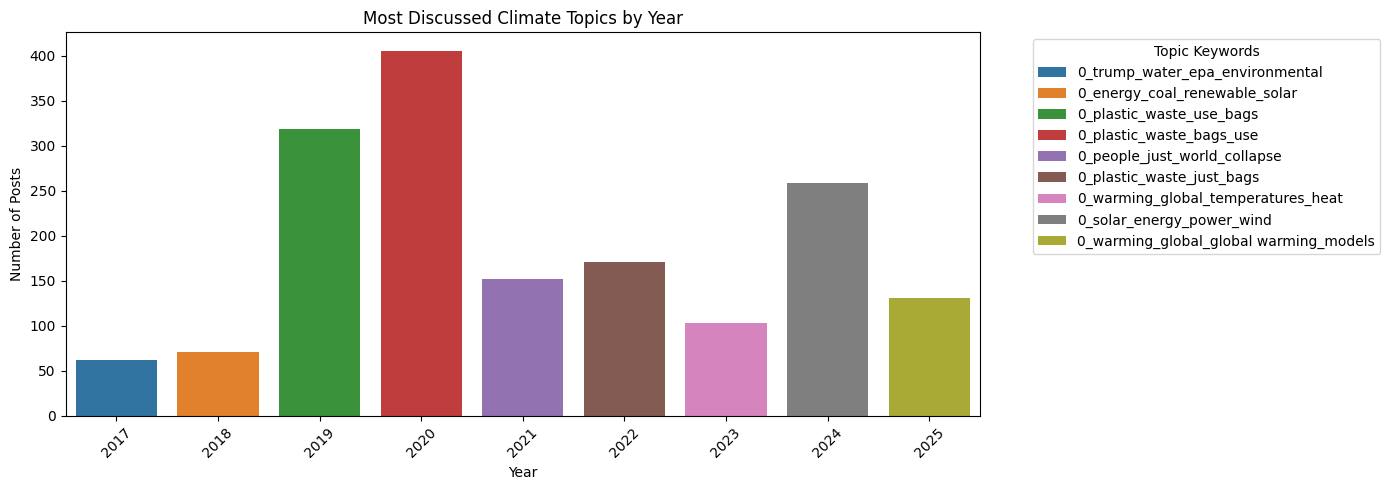

In [115]:
plt.figure(figsize=(10, 5))
sns.barplot(data=topic_summary_df, x='year', y='topic_size', hue='topic_words')
plt.title("Most Discussed Climate Topics by Year")
plt.xlabel("Year")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.legend(title='Topic Keywords', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

- We see different topics trending in each years like trump,renewable energy,plastic,people,plastic,global warming,sola.

- ### Latent Dirichlet Allocation  for topic modelling.

- Removing some obvious words 

In [116]:
stop_words = stopwords.words('english') + ['climate', 'change', 'climatechange',"like", "just", "one", "people", "think", "know", "time", "get", "going", "would", "make", "see", "say", "really", "good", "bad"]
texts = df['text'].astype(str).tolist()

In [117]:
count_vectorizer = CountVectorizer(stop_words=stop_words, max_df=0.95, min_df=5, ngram_range=(2, 2))
count_data = count_vectorizer.fit_transform(texts)
lda_model = LatentDirichletAllocation(n_components=10, random_state=42)
lda_topics = lda_model.fit_transform(count_data)


In [118]:
def display_topics(model, feature_names, no_top_words=10):
    for idx, topic in enumerate(model.components_):
        print(f"\nTopic {idx}:")
        print(", ".join([feature_names[i] for i in topic.argsort()[:-no_top_words - 1:-1]]))

display_topics(lda_model, count_vectorizer.get_feature_names_out())



Topic 0:
zero waste, plant based, next year, global warming, animal agriculture, al gore, carbon footprint, land use, extreme heat, year old

Topic 1:
global warming, sea level, level rise, solar power, supreme court, net zero, extreme weather, rooftop solar, tipping point, renewable energy

Topic 2:
fossil fuel, fossil fuels, elon musk, big oil, renewable energy, wind turbines, oil gas, green energy, fuel industry, trump administration

Topic 3:
renewable energy, offshore wind, tl dr, 100 renewable, constructive feedback, dr could, best tl, extended summary, welcome top, original reduced

Topic 4:
message compose, action performed, performed automatically, bot action, moderators subreddit, contact moderators, please contact, questions concerns, subreddit message, automatically please

Topic 5:
solar panels, single use, donald trump, new deal, green new, use plastic, heat wave, use plastics, ocasio cortez, trump administration

Topic 6:
years ago, last year, greta thunberg, wind solar

The function display_topics is used to print the top words that define each topic in your trained LDA.

- The 10 topic can be divided into general forms as below.

In [119]:
topic_labels = {
    0: "Zero waste & Planting ",
    1: "Climate Change Effects",
    2: "Fossil Fuel",
    3: "Renewable Energy & Technology",
    4: "Meta/moderation messages",
    5: "Trump & New Deal",
    6: "Energy Transition",
    7: "Clean Energy & Sustainability",
    8: "US politics",
    9: "Metadata & Miscellaneous"
}


In [120]:
texts = df['text'].tolist()
topics, probs = topic_model.transform(texts)
# Assign the dominant topic to each post
df['dominant_topic'] = topics

df['topic_label'] = df['dominant_topic'].map(topic_labels)


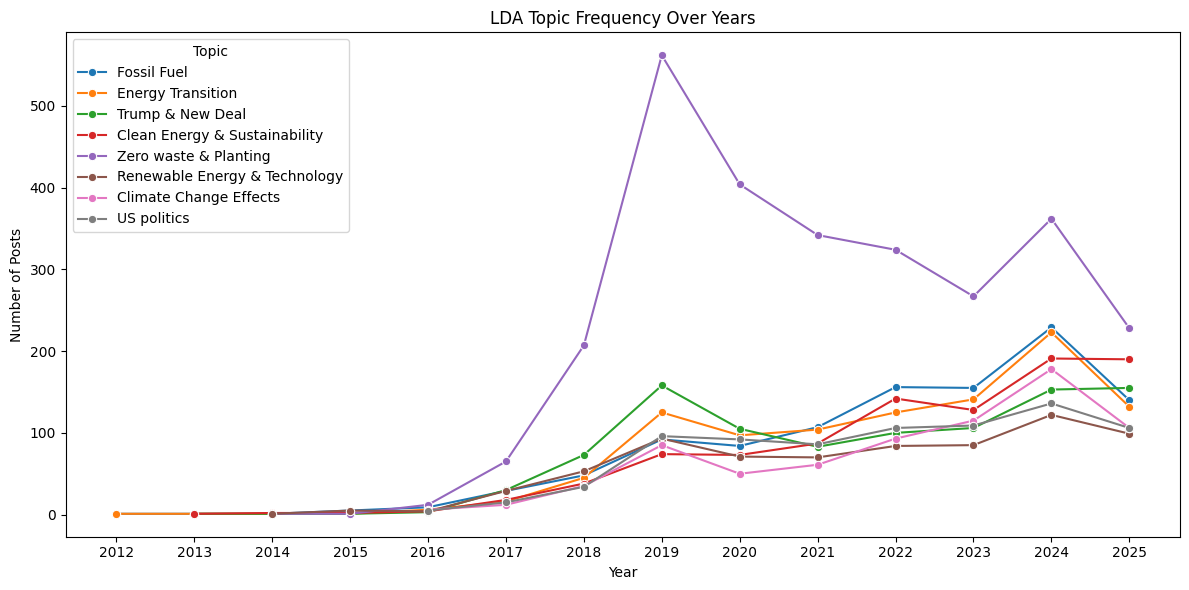

In [123]:
df['lda_topic'] = lda_topics.argmax(axis=1)
topic_counts_by_year = df.groupby(['year', 'lda_topic']).size().reset_index(name='count')

topic_counts_by_year['topic'] = topic_counts_by_year['lda_topic'].map(topic_labels)

exclude_topics = ["Meta/moderation messages", "Metadata & Miscellaneous"]
topic_counts_by_year = topic_counts_by_year[~topic_counts_by_year['topic'].isin(exclude_topics)]


plt.figure(figsize=(12, 6))
sns.lineplot(
    data=topic_counts_by_year,
    x='year',
    y='count',
    hue='topic',
    marker='o',
    palette='tab10'
)
plt.title('LDA Topic Frequency Over Years')
plt.xlabel('Year')
plt.ylabel('Number of Posts')
plt.legend(title='Topic')
plt.tight_layout()
plt.show()


- Climate discusions gets traction only after 2016.
- Most topics show erratic but increasing trend until 2024 where there is a significant dip in the discussions.

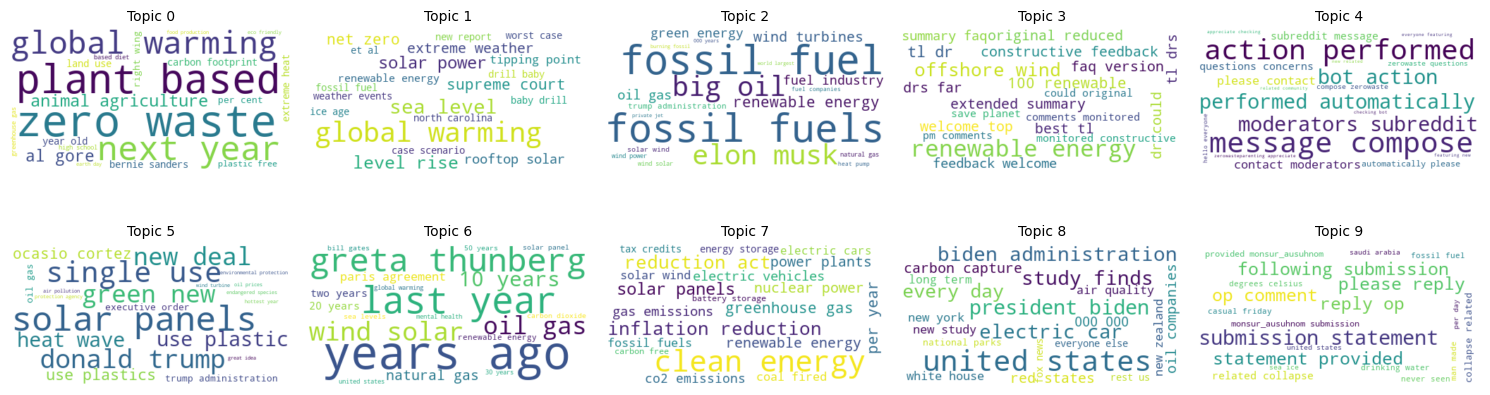

In [132]:
def plot_wordclouds_grid(model, feature_names, num_topics=10, cols=5):
    rows = math.ceil(num_topics / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 2.5))
   

    for idx, topic in enumerate(model.components_[:num_topics]):
        words = {feature_names[i]: topic[i] for i in topic.argsort()[:-21:-1]}
        wc = WordCloud(width=400, height=200, background_color='white').generate_from_frequencies(words)
        
        ax = axes[idx // cols, idx % cols]
        ax.imshow(wc, interpolation='bilinear')
        ax.set_title(f"Topic {idx}", fontsize=10)
        ax.axis('off')

   
    for i in range(num_topics, rows * cols):
        axes[i // cols, i % cols].axis('off')

    plt.tight_layout()
    plt.show()

plot_wordclouds_grid(lda_model, count_vectorizer.get_feature_names_out(), num_topics=10, cols=5)


- These are the relevant thems of the text on climate change.
- Looking at the image:

- Topic 0 seems to be about "global warming," "plant based," "zero waste," and "animal agriculture."
- Topic 1 seems to about global warming,seal level eise.
- Topic 2 is strongly associated with "fossil fuel," "big oil," and "renewable energy."
- Topic 5 is about solar panels and donald trump.
- Topic 6 centers around "greta thunberg," "wind solar," and "years ago."
- Topic 8 includes terms like "biden administration," "carbon capture," "united states," and "electric car."
- Topic 3,4,9 are metadata.

- ## Feature Importance

- We want to see what factor affect the enagement score.

- Reading the csv file with bert_sentiment and vader_sentiment which can be used as features to predict the enagagement score.

In [148]:
df.head(3)

,Date,subreddit,text,text_length,engagement_score,vader_sentiment_score,vader_sentiment_label,bert_sentiment_raw,bert_sentiment_score,bert_sentiment_label,engagement_bin,emotion_labels,emotion_scores,year,text_cleaned,dominant_topic,topic_label,lda_topic
0,2025-01-13 21:55:09,climatechange,We’ve Crossed a Key Threshold for Climate Chan...,34,9.413444,-0.5267,negative,LABEL_0,0.556520,negative,High (7.8+),"[approval, neutral]","[0.59, 0.447]",2025,We’ve Crossed a Key Threshold for . There’s No...,0,Zero waste & Planting,0
1,2024-12-23 11:51:10,climatechange,Venezuela is the first country to lose all of ...,21,8.860357,-0.4019,negative,LABEL_0,0.631578,negative,High (7.8+),[neutral],[0.712],2024,Venezuela is the first country to lose all of ...,0,Zero waste & Planting,7
2,2024-10-18 18:01:14,climatechange,Harris win would be a 'big relief' for climate...,35,8.493310,0.9642,positive,LABEL_2,0.701121,positive,High (7.8+),"[approval, optimism]","[0.354, 0.352]",2024,"Harris win would be a 'big relief' for , says ...",-1,NaN,1


<Axes: >

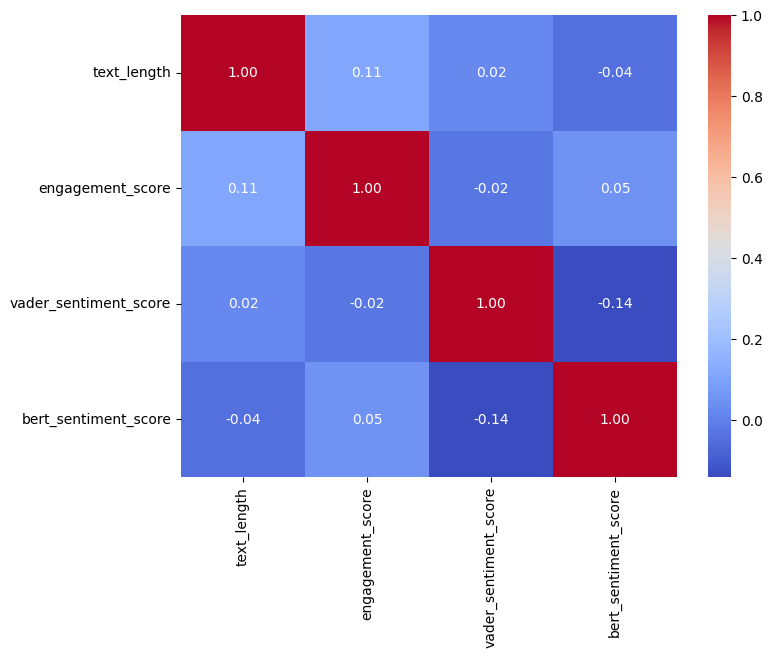

In [149]:
corr = df[['text_length', 'engagement_score','vader_sentiment_score','bert_sentiment_score']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

- There is very low correaltion  between features

- ### We can to predict the engagement score of the post basedon text,text_length,subrredit and sentimnents of the post.
- Features: text,text_length,subrredit,vader_sentiment_score,bert_sentiment_score
- Target : Engagement_score

In [150]:
X = df[['text', 'text_length', 'subreddit', 'vader_sentiment_score', 'bert_sentiment_score']]
y = df['engagement_score']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

- We used TF-IDF for text column we used 1000 max_features from text,subbredit is a categorical variable so it is one-hot encoded and scaling the numerical features.
- We used RandomForestRegression to predict the enagagaement score.

In [151]:
text_features = 'text'
numeric_features = ['text_length', 'vader_sentiment_score', 'bert_sentiment_score']
categorical_features = ['subreddit']

preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=1000), text_features),
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ]
)


model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])


model.fit(X_train, y_train)
y_pred = model.predict(X_test)


In [152]:
rmse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"R^2: {r2:.2f}")

RMSE: 0.34
MAE: 0.41
R^2: 0.80


In [153]:

text_features = model.named_steps['preprocessor'].named_transformers_['text'].get_feature_names_out()
numeric_features = ['text_length', 'vader_sentiment_score', 'bert_sentiment_score']
cat_features = model.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out()

all_features = list(text_features) + numeric_features + list(cat_features)
importances = model.named_steps['regressor'].feature_importances_


importances_df = pd.DataFrame({
    'feature': all_features,
    'importance': importances
}).sort_values(by='importance', ascending=False)

print(importances_df.head(20))


                        feature  importance
1004      subreddit_EcoInternet    0.220579
1010      subreddit_environment    0.128783
1005        subreddit_ZeroWaste    0.122547
1003         subreddit_Collapse    0.107857
1000                text_length    0.058400
1006          subreddit_climate    0.058295
1009           subreddit_energy    0.040896
1011  subreddit_renewableenergy    0.032355
1008  subreddit_climateskeptics    0.022302
1007    subreddit_climatechange    0.007692
1012   subreddit_sustainability    0.007009
903                       trump    0.006203
1002       bert_sentiment_score    0.005357
1001      vader_sentiment_score    0.005087
886                          to    0.002722
860                         the    0.002715
605                          of    0.002691
467                          it    0.002337
443                          in    0.002286
62                          and    0.002082


- We can see that in which subrredit the post is posted determined the enagement score of the posts.
- Text_length has feature importance of 5% which shows text_lenth has infulence on enagement_score.

- Now,let's use XGboost which is considered better than Random Forest. I used GridSearchCV to find the optimal parameters for better RMSE in XGboost.

In [154]:
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(
        objective='reg:squarederror',
        eval_metric='rmse',
        random_state=42,
        verbosity=0
    ))
])
param_grid = {
    'regressor__n_estimators': [100, 200],
    'regressor__max_depth': [3, 6],
    'regressor__learning_rate': [0.1, 0.05],
    'regressor__subsample': [0.8, 1.0],
}


In [155]:
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error', 
    cv=3,
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Score (neg RMSE):", grid_search.best_score_)


best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)


Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best Parameters: {'regressor__learning_rate': 0.1, 'regressor__max_depth': 3, 'regressor__n_estimators': 200, 'regressor__subsample': 0.8}
Best Score (neg RMSE): -0.5649158828056112


In [156]:
xgb_model = best_model.named_steps['regressor']


In [157]:
# Get names from each transformer
text_feats = best_model.named_steps['preprocessor'].named_transformers_['text'].get_feature_names_out()
num_feats = ['text_length', 'vader_sentiment_score', 'bert_sentiment_score']
cat_feats = best_model.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out()


all_feature_names = list(text_feats) + num_feats + list(cat_feats)

importance_scores = xgb_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'feature': all_feature_names,
    'importance': importance_scores
}).sort_values(by='importance', ascending=False)

print(feature_importance_df.head(20))


                        feature  importance
1004      subreddit_EcoInternet    0.108313
1011  subreddit_renewableenergy    0.092555
1010      subreddit_environment    0.087976
1003         subreddit_Collapse    0.078588
1008  subreddit_climateskeptics    0.073648
1005        subreddit_ZeroWaste    0.065557
1000                text_length    0.035187
1006          subreddit_climate    0.022483
1012   subreddit_sustainability    0.018019
1007    subreddit_climatechange    0.007267
1009           subreddit_energy    0.006649
903                       trump    0.004891
645                      person    0.003996
631                      panels    0.003302
592                          no    0.003067
885                          tl    0.003028
247                        down    0.002956
525                        lots    0.002740
649                      planet    0.002724
896                  transition    0.002698


- plotting the feature importance pie-chart.

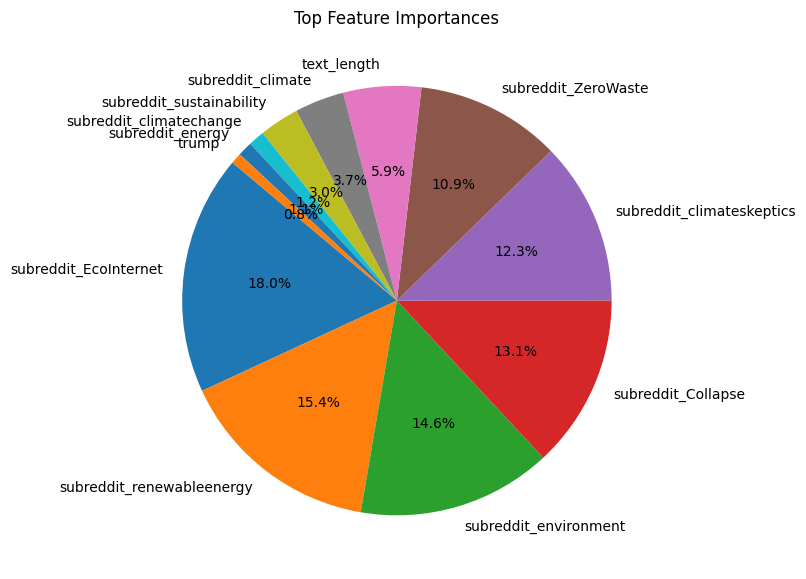

In [158]:
top_n = 12
top_features = feature_importance_df.head(top_n)
plt.figure(figsize=(8, 8))
plt.pie(top_features['importance'], labels=top_features['feature'], autopct='%1.1f%%', startangle=140)
plt.title(f"Top Feature Importances")
plt.tight_layout()
plt.show()

- We clearly see that in which subreddit discussion group was it posted has the greater infulence on engagemant score.
- This might be due to the fact that the number of members,active users or number of posts per day differ in subreddit groups.

## Future works :
- This project can be used to predict sentiment labels/scores based on other features.
- Also,this can be extended to use multiple text preprocessing techniques,embeddings model for prediction.
